Python DA Assignment 2 - Data Visualization

In [1]:
pip install numpy

Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [3]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [4]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# 1) Loading the Taxis Dataset

In [2]:
df = sns.load_dataset("taxis")

In [3]:
print(df.head())

               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Side South      

In [ ]:
# 2) Handling Missing Values
# ➢ Check for missing values in the dataset and identify columns with missing data.
# ➢ Impute missing values using appropriate strategies based on the column type (e.g.,
# using mean, median, or mode for numerical columns, and mode for categorical
# columns).
# ➢ For columns that are critical and cannot be reasonably imputed, remove rows with
# missing values to maintain data integrity.


In [4]:
print(df.isnull().sum())

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [5]:
num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

cat_cols = df.select_dtypes(exclude=np.number).columns

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

df = df.dropna(subset=["pickup", "fare"])

print(df.isnull().sum())

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


In [ ]:
# 3) Visualizations using Matplotlib/Pandas Plot:
# ★ Line Chart
# Plot a line chart to visualize the fare over time, using the pickup timestamp as the
# x-axis and fare as the y-axis. Ensure the pickup column is converted to a datetime
# format before plotting.
# ★ Bar Chart
# Create a bar chart to show the total fare for each pickup_borough. Group the data
# by pickup_borough and sum the fare for each group.
# ★ Pie Chart
# Plot a pie chart showing the distribution of trips based on the payment method (credit
# card, cash, etc.). Each slice should represent the count of trips for a specific payment
# method.
# ★ Histogram
# Create a histogram to visualize the distribution of distance. Customize the number of
# bins for better granularity and ensure the plot is easy to interpret.
# ★ Box Plot
# Plot a box plot to visualize the distribution of tip amounts for each pickup_borough.
# Use pickup_borough as the categorical axis and tip as the numeric axis.


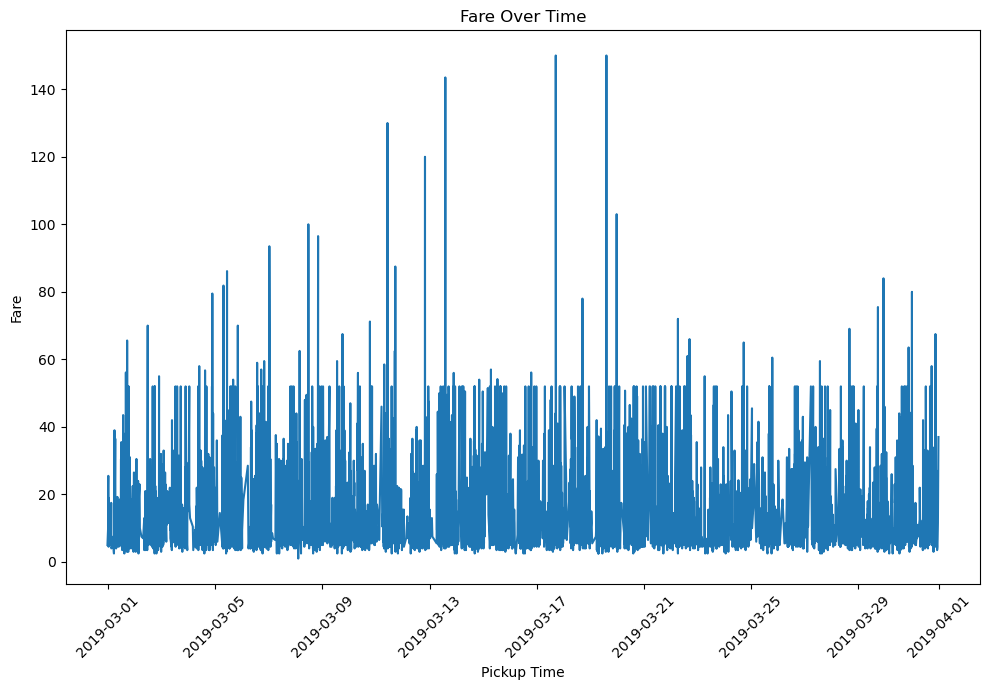

In [9]:
df["pickup"] = pd.to_datetime(df["pickup"])

line_df = df.sort_values("pickup")

plt.figure(figsize=(10,7))
plt.plot(line_df["pickup"], line_df["fare"])

plt.title("Fare Over Time")
plt.xlabel("Pickup Time")
plt.ylabel("Fare")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

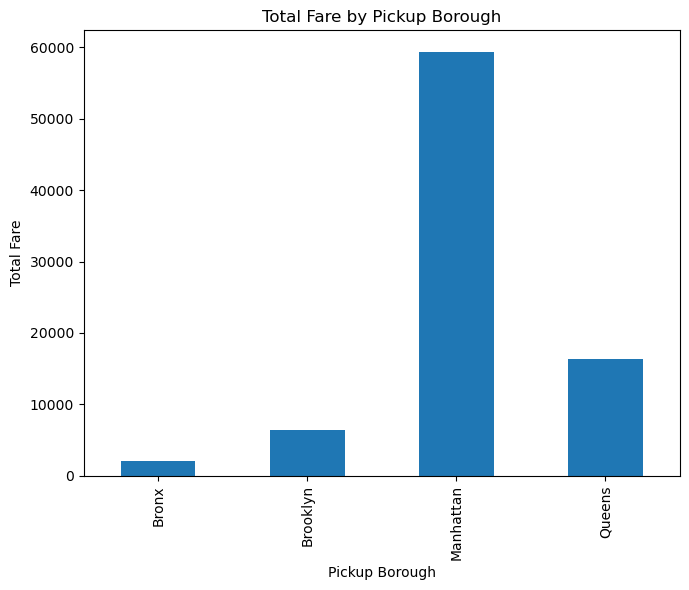

In [8]:
borough_fare = df.groupby("pickup_borough")["fare"].sum()

borough_fare.plot(kind="bar", figsize=(7,6))

plt.title("Total Fare by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")

plt.tight_layout()
plt.show()

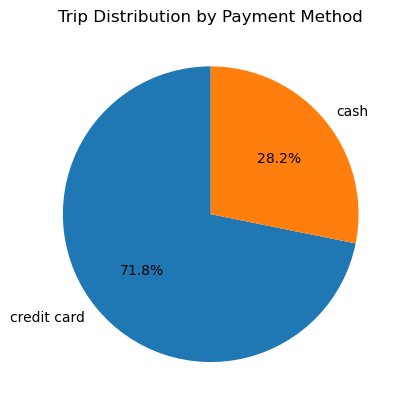

In [10]:
payment_counts = df["payment"].value_counts()

payment_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Trip Distribution by Payment Method")
plt.ylabel("")

plt.show()

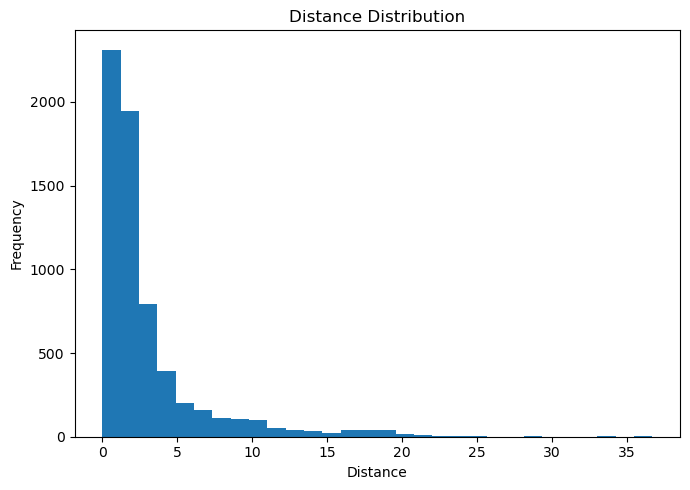

In [11]:
plt.figure(figsize=(7,5))

plt.hist(df["distance"], bins=30)

plt.title("Distance Distribution")
plt.xlabel("Distance")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

C:\Users\SRINI\AppData\Local\Temp\ipykernel_18112\3990762583.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(tip_data, labels=boroughs)


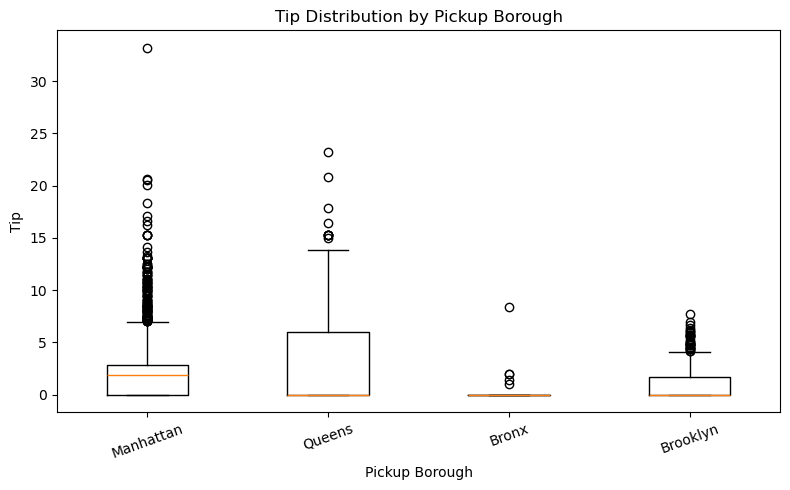

In [12]:
boroughs = df["pickup_borough"].dropna().unique()

tip_data = []

for b in boroughs:
    tip_data.append(df[df["pickup_borough"] == b]["tip"])

plt.figure(figsize=(8,5))

plt.boxplot(tip_data, labels=boroughs)

plt.title("Tip Distribution by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip")

plt.xticks(rotation=20)
plt.tight_layout()

plt.show()

Visualizations using Seaborn:

In [ ]:
#  Count Plot
# Create a count plot to visualize the number of trips in each pickup_borough. The
# x-axis should represent the boroughs, and the y-axis should show the count of trips.
# ★ Scatter Plot
# Plot a scatter plot to show the relationship between distance and fare. Use
# distance on the x-axis and fare on the y-axis to visualize any correlation. Color the
# points based on the pickup_borough to differentiate the trips by their respective
# boroughs.
# ★ Heatmap
# Plot a heatmap to visualize the correlation between numerical variables such as
# distance, fare, tip, tolls, and total. Use a correlation matrix to highlight the
# relationships.
# ★ Pair Plot
# Create a pair plot to visualize the pairwise relationships between distance, fare, tip,
# and total. Color the data points according to the pickup_zone method to compare
# how different zones affect these variables.
# ★ Violin Plot
# Plot a violin plot to show the distribution of fare for each payment method. Use the
# payment method as the categorical axis and fare as the numeric axis to visualize its
# distribution.

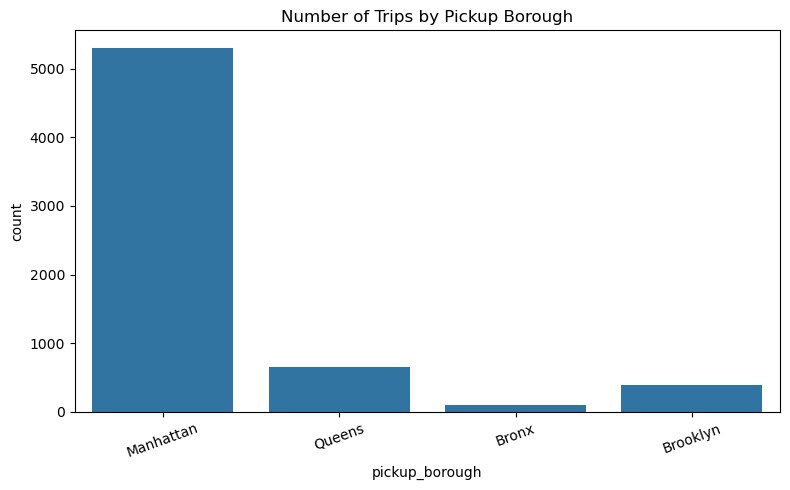

In [13]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x="pickup_borough")

plt.title("Number of Trips by Pickup Borough")

plt.xticks(rotation=20)
plt.tight_layout()

plt.show()

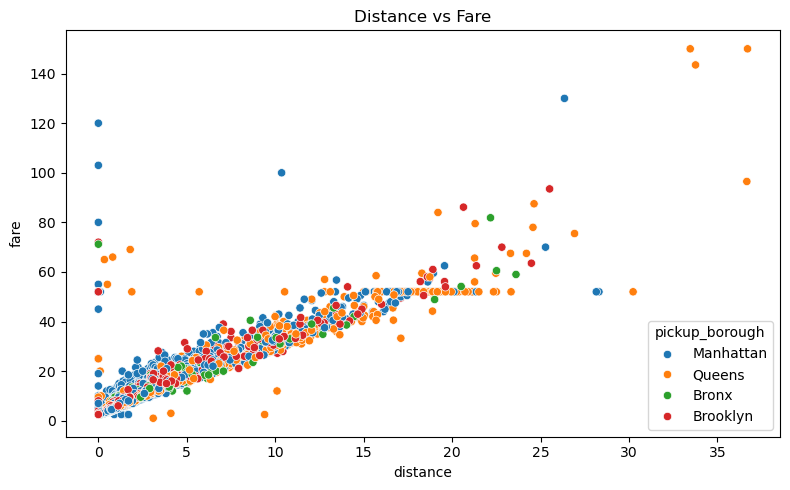

In [14]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="distance",
    y="fare",
    hue="pickup_borough"
)

plt.title("Distance vs Fare")

plt.tight_layout()
plt.show()

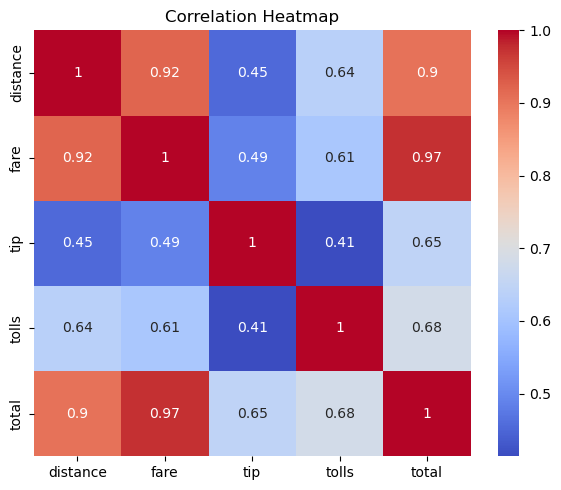

In [15]:
corr = df[["distance", "fare", "tip", "tolls", "total"]].corr()

plt.figure(figsize=(6,5))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()

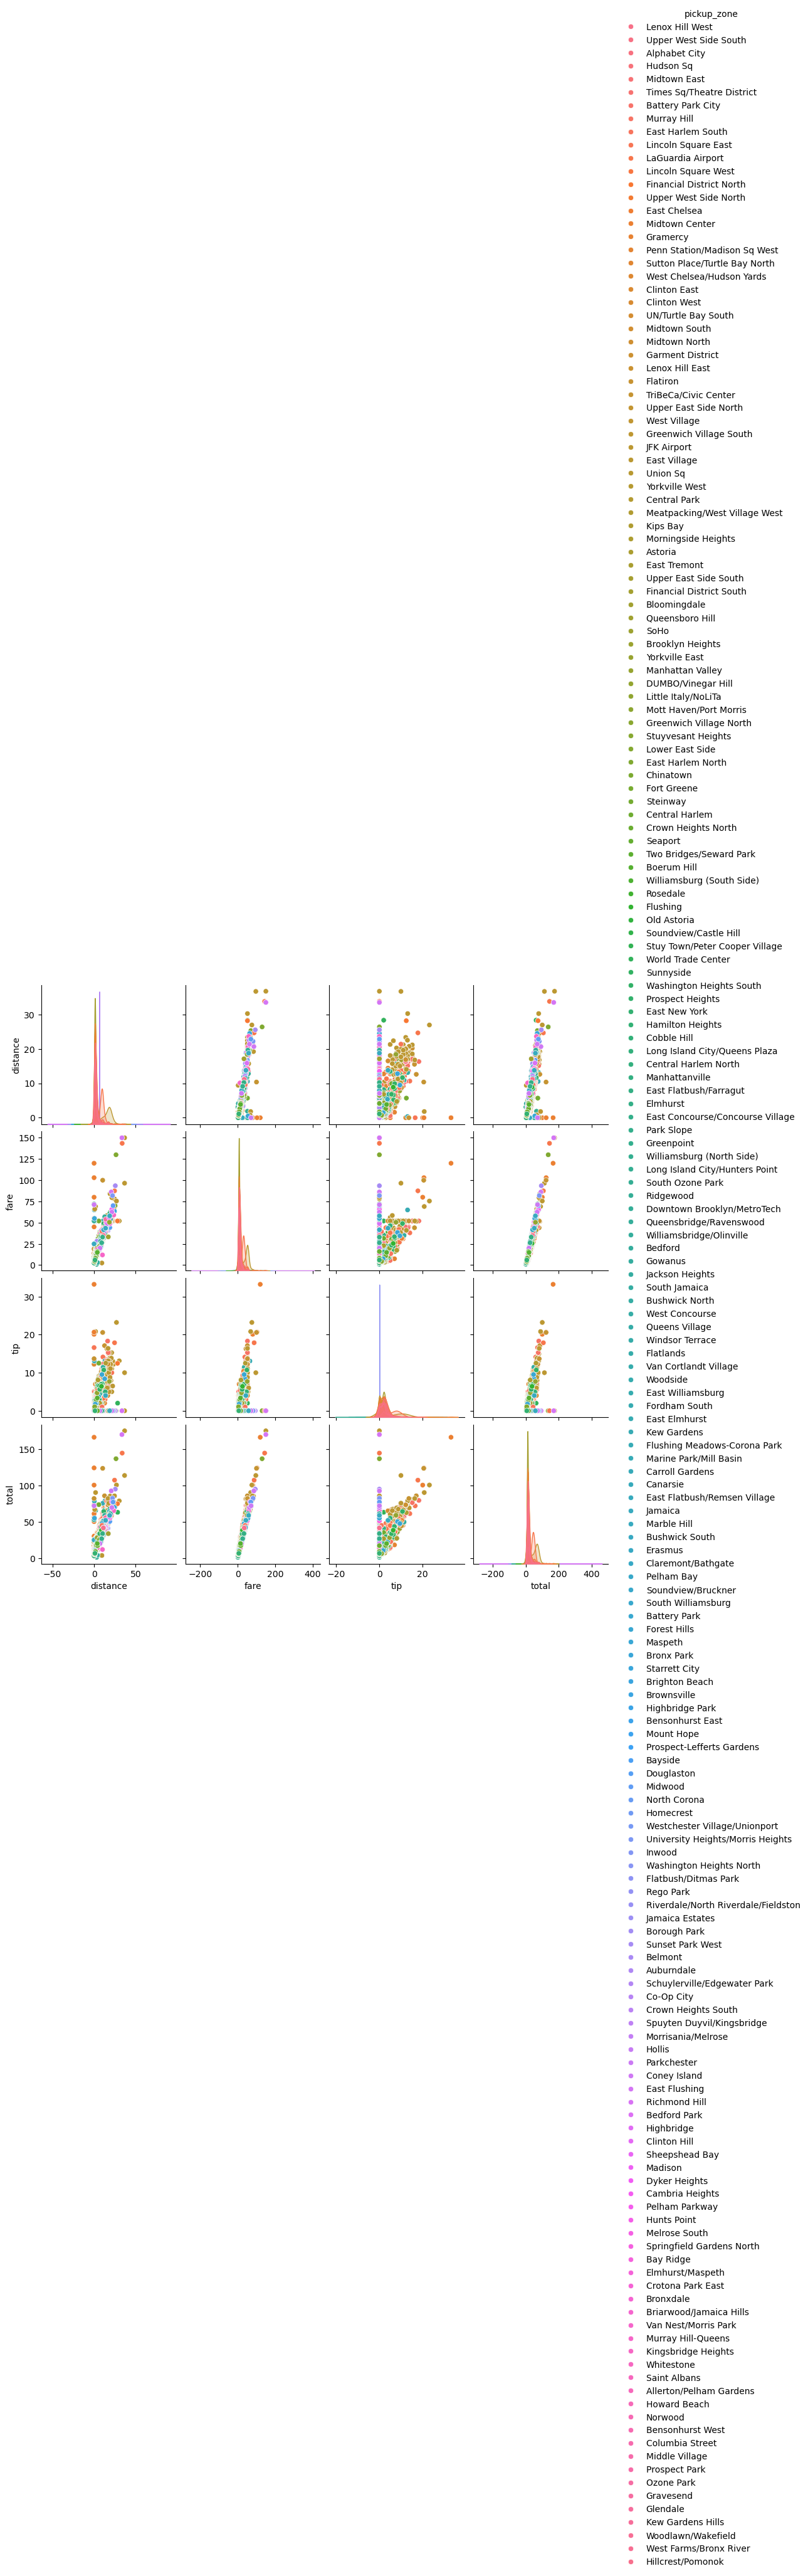

In [17]:
sns.pairplot(
    df[["distance", "fare", "tip", "total", "pickup_zone"]],
    hue="pickup_zone"
)

plt.show()

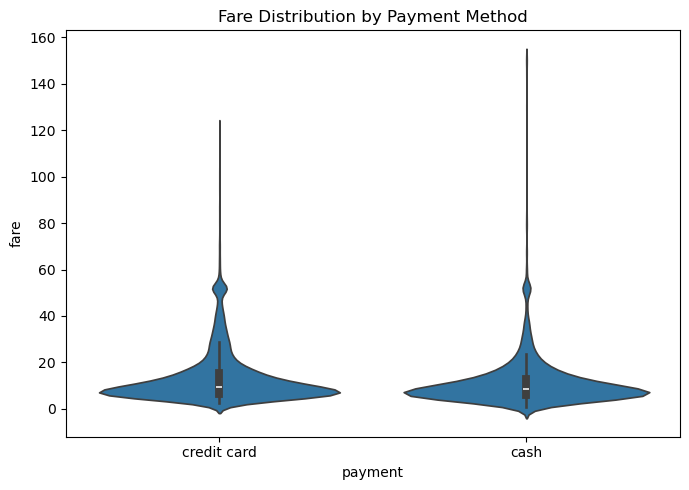

In [18]:
plt.figure(figsize=(7,5))

sns.violinplot(
    data=df,
    x="payment",
    y="fare"
)

plt.title("Fare Distribution by Payment Method")

plt.tight_layout()
plt.show()